In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

In [2]:
df = pd.read_csv('order_items.csv')
df.head()

,order_item_id,order_id,product_id,quantity,unit_price,discount_pct,line_total
0,OI000136,O00309,P054,4,20481.04,10,73731.74
1,OI000768,O00160,P059,1,18828.50,0,18828.50
2,OI000646,O00066,P055,5,5471.28,0,27356.40
3,OI000594,O00136,P062,4,8493.72,0,33974.88
4,OI000129,O00285,P062,1,8493.72,0,4246.86


In [3]:
df.shape

(802, 7)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 802 entries, 0 to 801
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_item_id  802 non-null    str    
 1   order_id       802 non-null    str    
 2   product_id     802 non-null    str    
 3   quantity       802 non-null    int64  
 4   unit_price     797 non-null    float64
 5   discount_pct   802 non-null    int64  
 6   line_total     802 non-null    float64
dtypes: float64(2), int64(2), str(3)
memory usage: 44.0 KB


In [5]:
df.isnull().sum()

order_item_id    0
order_id         0
product_id       0
quantity         0
unit_price       5
discount_pct     0
line_total       0
dtype: int64

In [6]:
print(df.duplicated().sum())
print(df['order_item_id'].duplicated().sum())
df[df['order_item_id'].duplicated(keep=False)].sort_values('order_item_id')

5
5


,order_item_id,order_id,product_id,quantity,unit_price,discount_pct,line_total
184,OI000001,O00079,P009,3,26274.11,5,74881.21
386,OI000001,O00079,P009,3,26274.11,5,74881.21
239,OI000176,O00070,P055,2,5471.28,5,10395.43
475,OI000176,O00070,P055,2,5471.28,5,10395.43
200,OI000255,O00120,P061,4,8318.56,20,26619.39
245,OI000255,O00120,P061,4,8318.56,20,26619.39
221,OI000434,O00135,P048,1,25643.17,0,25643.17
584,OI000434,O00135,P048,1,25643.17,0,25643.17
346,OI000674,O00008,P014,2,13809.86,0,27619.72
735,OI000674,O00008,P014,2,13809.86,0,27619.72


In [7]:
df.describe()

,quantity,unit_price,discount_pct,line_total
count,802.000000,797.000000,802.000000,802.000000
mean,3.013716,13097.822083,8.908978,37470.416359
std,1.574948,7489.046351,12.562968,30713.449637
min,-5.000000,-70.380000,-10.000000,-351.900000
25%,2.000000,7218.530000,0.000000,13744.887500
50%,3.000000,11992.920000,5.000000,28363.565000
75%,4.000000,20098.630000,15.000000,55459.480000
max,5.000000,27280.240000,150.000000,200986.300000


In [8]:
print(df['quantity'].value_counts().sort_index())
print()
print(df['discount_pct'].value_counts().sort_index())

quantity
-5      3
-4      3
 0      4
 1    153
 2    145
 3    143
 4    183
 5    168
Name: count, dtype: int64

discount_pct
-10       3
 0      271
 5      133
 10     138
 15     106
 20     147
 150      4
Name: count, dtype: int64


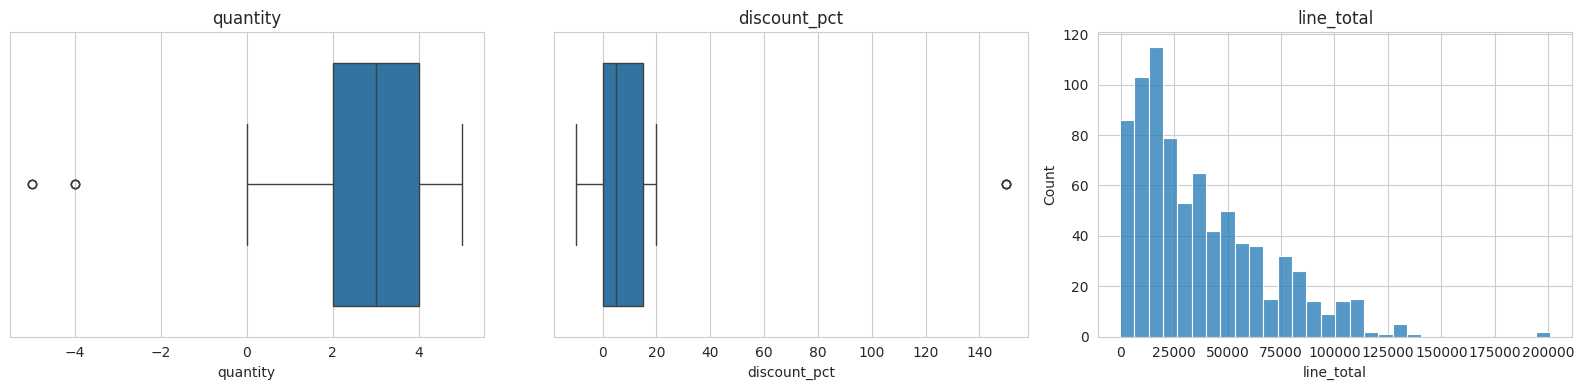

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(x=df['quantity'], ax=ax[0])
sns.boxplot(x=df['discount_pct'], ax=ax[1])
sns.histplot(df['line_total'], bins=30, ax=ax[2])
ax[0].set_title('quantity')
ax[1].set_title('discount_pct')
ax[2].set_title('line_total')
plt.tight_layout()
plt.show()

In [10]:
calc = (df['quantity'] * df['unit_price'] * (1 - df['discount_pct'] / 100)).round(2)
mismatch = (calc - df['line_total']).abs() > 0.05
print(mismatch.sum())
pd.concat([df, calc.rename('calc_total')], axis=1)[mismatch].head(15)

46


,order_item_id,order_id,product_id,quantity,unit_price,discount_pct,line_total,calc_total
4,OI000129,O00285,P062,1,8493.72,0,4246.86,8493.72
13,OI000120,O00041,P009,2,26274.11,-10,49920.81,57803.04
85,OI000125,O00091,P015,5,4516.10,150,22580.50,-11290.25
95,OI000496,O00034,P065,5,15706.03,20,50259.30,62824.12
137,OI000190,O00030,P062,1,8493.72,0,16987.44,8493.72
139,OI000377,O00278,P063,0,9269.43,5,8805.96,0.00
185,OI000731,O00185,P036,1,4574.41,20,2927.62,3659.53
189,OI000123,O00091,P031,4,20098.63,-10,76374.79,88433.97
271,OI000334,O00090,P057,1,11518.86,0,23037.72,11518.86
291,OI000394,O00200,P022,5,19552.29,0,195522.90,97761.45


In [11]:
df[df['unit_price'].isnull() | (df['unit_price'] <= 0)]

,order_item_id,order_id,product_id,quantity,unit_price,discount_pct,line_total
15,OI000519,O00163,P008,4,NaN,15,51601.73
78,OI000431,O00314,P003,1,-70.38,20,-56.30
88,OI000016,O00265,P003,3,-70.38,5,-200.58
170,OI000183,O00047,P003,1,-70.38,20,-56.30
191,OI000373,O00151,P052,3,NaN,0,52911.84
201,OI000305,O00031,P003,3,-70.38,5,-200.58
235,OI000161,O00210,P003,2,-70.38,5,-133.72
302,OI000290,O00084,P003,5,-70.38,20,-281.52
324,OI000558,O00183,P040,3,NaN,0,6060.33
516,OI000737,O00062,P003,4,-70.38,20,-225.22


In [12]:
orders = pd.read_csv('orders_clean.csv')
prod = pd.read_csv('products_clean.csv')
print(sorted(set(df['order_id']) - set(orders['order_id'])))
print(sorted(set(df['product_id']) - set(prod['product_id'])))

['O90859', 'O91922', 'O92434', 'O92943', 'O94014', 'O95545', 'O96619', 'O97107', 'O98444', 'O99722']
['P922', 'P948', 'P983', 'P984', 'P985', 'P988', 'P995', 'P999']


In [13]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(before, '->', len(df))
df['order_item_id'].duplicated().sum()

802 -> 797


np.int64(0)

In [14]:
bad_qty = df['quantity'] <= 0
rejects = df[bad_qty].copy()
rejects['reject_reason'] = 'quantity <= 0'
print(bad_qty.sum())
rejects

10


,order_item_id,order_id,product_id,quantity,unit_price,discount_pct,line_total,reject_reason
139,OI000377,O00278,P063,0,9269.43,5,8805.96,quantity <= 0
413,OI000669,O00289,P009,0,26274.11,0,26274.11,quantity <= 0
495,OI000797,O00096,P031,-5,20098.63,0,100493.15,quantity <= 0
499,OI000392,O00200,P037,-5,16084.14,5,76399.66,quantity <= 0
507,OI000282,O00043,P027,-4,20550.39,5,78091.48,quantity <= 0
536,OI000648,O00063,P062,0,8493.72,10,30577.39,quantity <= 0
572,OI000475,O00039,P015,-5,4516.10,0,22580.50,quantity <= 0
707,OI000092,O00104,P025,-4,19632.52,20,62824.06,quantity <= 0
752,OI000666,O00105,P006,-4,2863.09,10,10307.12,quantity <= 0
790,OI000456,O00228,P014,0,13809.86,20,11047.89,quantity <= 0


In [15]:
df = df[~bad_qty].reset_index(drop=True)
df.shape

(787, 7)

In [16]:
price_lookup = prod.set_index('product_id')['unit_price']
implied_price = df['line_total'] / (df['quantity'] * (1 - df['discount_pct'] / 100))
missing_price = df['unit_price'].isnull()
negative_price = df['unit_price'] <= 0
print(missing_price.sum(), negative_price.sum())

5 10


In [17]:
df.loc[missing_price, 'unit_price'] = implied_price[missing_price].round(2)
df.loc[negative_price, 'unit_price'] = df.loc[negative_price, 'product_id'].map(price_lookup)
df['unit_price'].isnull().sum()

np.int64(0)

In [18]:
list_price = df['product_id'].map(price_lookup)
print(np.isclose(df['unit_price'], list_price).mean())
df[~np.isclose(df['unit_price'], list_price) & list_price.notna()].head()

0.9669631512071156


,order_item_id,order_id,product_id,quantity,unit_price,discount_pct,line_total
559,OI000306,O00173,P045,2,32736.29,10,58925.32


In [19]:
valid_disc = [0, 5, 10, 15, 20]
bad_disc = ~df['discount_pct'].isin(valid_disc)
implied_disc = (1 - df['line_total'] / (df['quantity'] * df['unit_price'])) * 100
implied_disc = (implied_disc / 5).round() * 5
print(bad_disc.sum())
pd.concat([df.loc[bad_disc, ['order_item_id', 'discount_pct', 'line_total']], implied_disc[bad_disc].rename('implied_disc')], axis=1)

7


,order_item_id,discount_pct,line_total,implied_disc
13,OI000120,-10,49920.81,5.0
85,OI000125,150,22580.50,0.0
188,OI000123,-10,76374.79,5.0
292,OI000085,150,19756.85,15.0
307,OI000012,-10,11518.86,0.0
341,OI000657,150,28120.82,10.0
503,OI000501,150,17880.99,20.0


In [20]:
df.loc[bad_disc, 'discount_pct'] = implied_disc[bad_disc].where(implied_disc[bad_disc].isin(valid_disc))
print(df['discount_pct'].isnull().sum())
df['discount_pct'].value_counts().sort_index()

0


discount_pct
0     268
5     130
10    137
15    107
20    145
Name: count, dtype: int64

In [21]:
df['line_total_raw'] = df['line_total']
df['line_total'] = (df['quantity'] * df['unit_price'] * (1 - df['discount_pct'] / 100)).round(2)
df['total_fixed'] = (df['line_total'] - df['line_total_raw']).abs() > 0.05
print(df['total_fixed'].sum())
df[df['total_fixed']].head(10)

39


,order_item_id,order_id,product_id,quantity,unit_price,discount_pct,line_total,line_total_raw,total_fixed
4,OI000129,O00285,P062,1,8493.72,0,8493.72,4246.86,True
78,OI000431,O00314,P003,1,9543.98,20,7635.18,-56.30,True
88,OI000016,O00265,P003,3,9543.98,5,27200.34,-200.58,True
95,OI000496,O00034,P065,5,15706.03,20,62824.12,50259.30,True
137,OI000190,O00030,P062,1,8493.72,0,8493.72,16987.44,True
169,OI000183,O00047,P003,1,9543.98,20,7635.18,-56.30,True
184,OI000731,O00185,P036,1,4574.41,20,3659.53,2927.62,True
200,OI000305,O00031,P003,3,9543.98,5,27200.34,-200.58,True
234,OI000161,O00210,P003,2,9543.98,5,18133.56,-133.72,True
269,OI000334,O00090,P057,1,11518.86,0,11518.86,23037.72,True


In [22]:
df['order_orphan'] = ~df['order_id'].isin(orders['order_id'])
df['product_orphan'] = ~df['product_id'].isin(prod['product_id'])
print(df['order_orphan'].sum(), df['product_orphan'].sum())

10 8


In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 787 entries, 0 to 786
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_item_id   787 non-null    str    
 1   order_id        787 non-null    str    
 2   product_id      787 non-null    str    
 3   quantity        787 non-null    int64  
 4   unit_price      787 non-null    float64
 5   discount_pct    787 non-null    int64  
 6   line_total      787 non-null    float64
 7   line_total_raw  787 non-null    float64
 8   total_fixed     787 non-null    bool   
 9   order_orphan    787 non-null    bool   
 10  product_orphan  787 non-null    bool   
dtypes: bool(3), float64(3), int64(2), str(3)
memory usage: 51.6 KB


In [24]:
df.isnull().sum()

order_item_id     0
order_id          0
product_id        0
quantity          0
unit_price        0
discount_pct      0
line_total        0
line_total_raw    0
total_fixed       0
order_orphan      0
product_orphan    0
dtype: int64

In [25]:
df.describe()

,quantity,unit_price,discount_pct,line_total,line_total_raw
count,787.000000,787.000000,787.000000,787.000000,787.000000
mean,3.090216,13200.613901,8.290978,37287.120267,37431.656518
std,1.426126,7365.243176,7.560306,29013.569103,30738.890132
min,1.000000,824.930000,0.000000,990.960000,-351.900000
25%,2.000000,7313.650000,0.000000,14098.430000,13766.545000
50%,3.000000,11992.920000,5.000000,29190.880000,28477.800000
75%,4.000000,20098.630000,15.000000,55379.770000,55379.770000
max,5.000000,32736.290000,20.000000,128215.850000,200986.300000


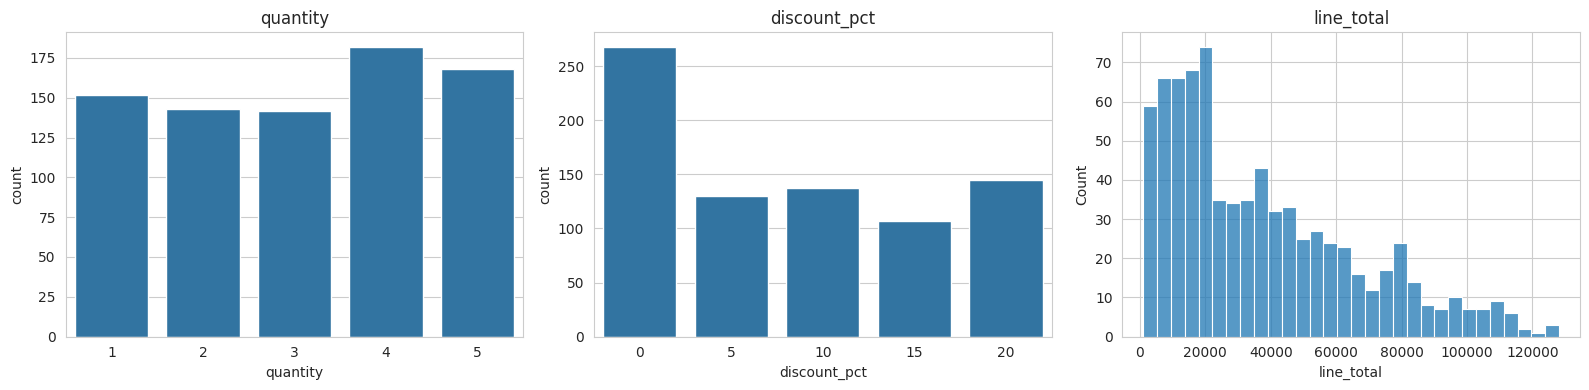

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x='quantity', ax=ax[0])
sns.countplot(data=df, x='discount_pct', ax=ax[1])
sns.histplot(df['line_total'], bins=30, ax=ax[2])
ax[0].set_title('quantity')
ax[1].set_title('discount_pct')
ax[2].set_title('line_total')
plt.tight_layout()
plt.show()

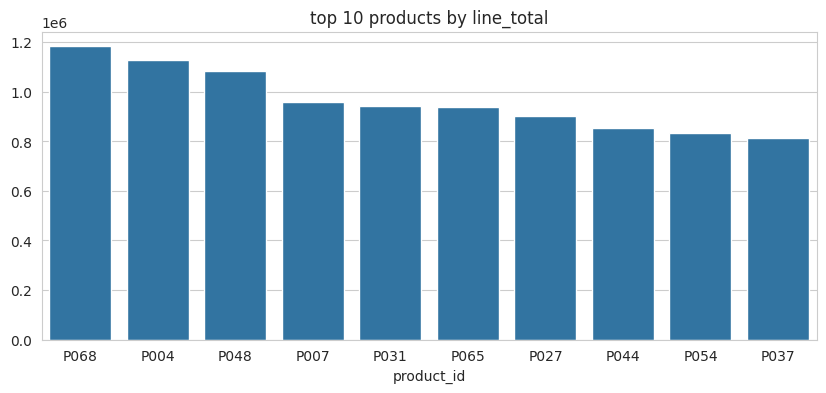

In [27]:
top = df.groupby('product_id')['line_total'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 4))
sns.barplot(x=top.index, y=top.values)
plt.title('top 10 products by line_total')
plt.show()

In [28]:
df.to_csv('order_items_clean.csv', index=False)
rejects.to_csv('order_items_rejected.csv', index=False)
df.head()

,order_item_id,order_id,product_id,quantity,unit_price,discount_pct,line_total,line_total_raw,total_fixed,order_orphan,product_orphan
0,OI000136,O00309,P054,4,20481.04,10,73731.74,73731.74,False,False,False
1,OI000768,O00160,P059,1,18828.50,0,18828.50,18828.50,False,False,False
2,OI000646,O00066,P055,5,5471.28,0,27356.40,27356.40,False,False,False
3,OI000594,O00136,P062,4,8493.72,0,33974.88,33974.88,False,False,False
4,OI000129,O00285,P062,1,8493.72,0,8493.72,4246.86,True,False,False
